# Endterm: predicting the furniture type from specifications

**Direction 21 - Furniture · classification · Machine Learning Algorithms, Endterm**
Team: Sultanbek Zhumagali, Tamerlan Yessimov (SE-2420)

**Question (unchanged since the Midterm).** Can the type of a furniture item (sofa, armchair, chair, bed, wardrobe, chest of drawers, desk, coffee table, TV stand) be predicted from its width, depth, height, materials, colour and price? A marketplace could use the answer to flag listings whose category disagrees with their numbers.

**What the Endterm adds to the Midterm** (same data, same saved test listings, same metric):

| Section | What | Endterm rubric criterion |
|---|---|---|
| 1 | Same data and split, the fixes promised in the Midterm, before/after evidence | 1. Continuity and fixes |
| 2 | Random forest and gradient boosting, tuned with grouped cross-validation; SVM re-tuned | 2. Tuned ensembles |
| 3 | PCA and k-means on the listings, interpreted and linked to the model's errors | 3. Unsupervised analysis |
| 4 | A neural network (MLP) with a learning-curve check | 4. Neural network |
| 5 | One table with every model, and the errors across models | 5. Fair comparison and errors |
| 6 | Conclusions, limitations and the plan for the Final | 6. Conclusions and plan |
| 7 | Who did what and AI tools | 8. Contributions |

**How to read this notebook.** Every section starts with a short *In plain words* note that explains the idea without jargon. The code cells follow, and every result is interpreted right after it. The change log is also in `CHANGES.md`.

## 0. Setup

> **In plain words.** Load the libraries, read the same cleaned table as at the Midterm, and rebuild the same input columns. Nothing here is new: it is the Midterm's preparation, repeated so this notebook runs on its own.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
from sklearn.base import clone

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import (StratifiedGroupKFold, GroupShuffleSplit, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.metrics import (f1_score, accuracy_score, classification_report, confusion_matrix,
                             silhouette_score, adjusted_rand_score)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # convergence is checked explicitly in section 4
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
TYPES = ["sofa", "armchair", "chair", "bed", "wardrobe", "chest_of_drawers", "desk", "coffee_table", "tv_stand"]
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

pandas 3.0.6 | scikit-learn 1.9.1 | numpy 2.5.3


In [2]:
df = pd.read_csv("data/processed/furniture.csv")

# The Midterm cleaning checks (section 2.1 there). They removed 0 rows, so here they are assertions.
sizes = df[["width_cm", "depth_cm", "height_cm"]]
assert not ((sizes < 10) | (sizes > 500)).any(axis=None), "impossible size"
assert (df["price_kzt"] >= 5_000).all(), "impossible price"
assert not df["url"].duplicated().any(), "duplicate URL"
df["main_color"] = df["main_color"].fillna("unknown")
df["materials"] = df["materials"].fillna("")

def add_features(d):
    # the same derived features as at the Midterm (section 2.4)
    d = d.copy()
    d["footprint_m2"] = d["width_cm"] * d["depth_cm"] / 1e4
    d["volume_m3"] = d["width_cm"] * d["depth_cm"] * d["height_cm"] / 1e6
    d["height_to_width"] = d["height_cm"] / d["width_cm"]
    d["depth_to_width"] = d["depth_cm"] / d["width_cm"]
    d["log_price"] = np.log(d["price_kzt"])
    d["log_price_per_m3"] = np.log(d["price_kzt"] / d["volume_m3"])
    mats = d["materials"].str.get_dummies(sep="|").add_prefix("mat_")
    return pd.concat([d, mats], axis=1)

df = add_features(df)
NUMERIC = ["width_cm", "depth_cm", "height_cm", "footprint_m2", "volume_m3", "height_to_width",
           "depth_to_width", "log_price", "log_price_per_m3"]
MATERIALS = sorted(c for c in df.columns if c.startswith("mat_"))
COLOUR = ["main_color"]
FEATURES = NUMERIC + MATERIALS + COLOUR
print(df.shape, "|", len(FEATURES), "input columns")

(3961, 35) | 25 input columns


> **In plain words.** A *pipeline* glues "prepare the inputs" and "the model" together. Because the scaler sits inside the pipeline, it is re-fitted on the training part of every fold and never sees the rows it is checked on. Every model in this notebook uses the same preparation, so the comparison is fair.

In [3]:
def make_prep():
    return ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC),                                            # sizes, ratios, prices -> mean 0, sd 1
        ("materials", "passthrough", MATERIALS),                                           # already 0/1 flags
        ("colour", OneHotEncoder(handle_unknown="ignore", min_frequency=10), COLOUR),      # rare colours grouped
    ])

def make_pipeline(model):
    return Pipeline([("prep", make_prep()), ("model", model)])

## 1. Continuity and fixes since the Midterm

### 1.1 The same test listings

> **In plain words.** The test set is the "final exam": 793 listings the models never learn from. We do **not** split again. We read the exact 793 URLs saved at the Midterm, so every score here can be compared with the Midterm.

In [4]:
test_urls = set(pd.read_csv("data/processed/test_urls.csv")["url"])
is_test = df["url"].isin(test_urls)
assert is_test.sum() == 793, "the saved test set has changed"
print("test listings:", int(is_test.sum()), "| other listings:", int((~is_test).sum()))

test listings: 793 | other listings: 3168


### 1.2 The two fixes promised in the Midterm plan

> **In plain words.** The store sells one model in many colours. If one colour is used for training and another for checking, the model only has to recognise the model, which is a kind of cheating. The Midterm kept all colours of a *series* together. Two gaps were left, and both are fixed here:
> 1. **97 listings have no series.** They were grouped by their own article number, so their colour twins were *not* kept together. Fix: colour variants share size, price and materials, so these listings are grouped by that exact combination.
> 2. **Some training listings are colour twins of test listings.** Fix: remove them from training. The test set itself does not change.

In [5]:
no_series = df["series"].astype(str) == df["sku"].astype(str)   # build_dataset.py used the SKU when there was no series
spec_key = df[["width_cm", "depth_cm", "height_cm", "price_kzt", "materials"]].astype(str).agg("|".join, axis=1)
df["group"] = np.where(no_series, "spec:" + spec_key, df["series"].astype(str))

test_groups = set(df.loc[is_test, "group"])
twin = (~is_test) & df["group"].isin(test_groups)

# How many test listings had a twin in training, before and after the fix?
old_twin_of_test = is_test & df["group"].isin(set(df.loc[~is_test, "group"]))
print("listings without a series:", int(no_series.sum()))
print("test listings with a colour twin in the Midterm training rows:", int(old_twin_of_test.sum()))
print("training listings removed (twins of test listings):", int(twin.sum()))

train, test = df[~is_test & ~twin], df[is_test]
X_train, y_train, g_train = train[FEATURES], train["furniture_type"], train["group"]
X_test, y_test = test[FEATURES], test["furniture_type"]
assert not set(g_train) & set(test["group"]), "a group is on both sides"
print(f"train: {len(train)} listings in {g_train.nunique()} groups | test: {len(test)} listings")

listings without a series: 97
test listings with a colour twin in the Midterm training rows: 14
training listings removed (twins of test listings): 41
train: 3127 listings in 359 groups | test: 793 listings


### 1.3 Before and after, with the Midterm's best model

> **In plain words.** Same model as the Midterm winner (SVM, C = 3), scored twice: with the Midterm setup and with the fixed one. This shows what the fixes changed.

In [6]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def before_after(model):
    old = df[~is_test]   # Midterm setup: all non-test rows, grouped by series
    r_old = cross_validate(make_pipeline(model), old[FEATURES], old["furniture_type"], groups=old["series"],
                           cv=cv, scoring="f1_macro")
    r_new = cross_validate(make_pipeline(model), X_train, y_train, groups=g_train, cv=cv, scoring="f1_macro")
    t_old = f1_score(y_test, make_pipeline(model).fit(old[FEATURES], old["furniture_type"]).predict(X_test), average="macro")
    t_new = f1_score(y_test, make_pipeline(model).fit(X_train, y_train).predict(X_test), average="macro")
    return pd.DataFrame({
        "training rows": [len(old), len(train)],
        "CV macro-F1": [r_old["test_score"].mean(), r_new["test_score"].mean()],
        "CV sd": [r_old["test_score"].std(), r_new["test_score"].std()],
        "test macro-F1": [t_old, t_new],
    }, index=["Midterm setup", "fixed setup"]).round(3)

before_after(SVC(C=3, gamma="scale"))

,training rows,CV macro-F1,CV sd,test macro-F1
Midterm setup,3168,0.941,0.024,0.978
fixed setup,3127,0.946,0.018,0.975


**What the fixes changed**
* 97 listings had no series. 14 test listings had a colour twin among the Midterm training rows. After the fix, **41 training listings** (all colour variants of test listings) are removed, and no group is on both sides (checked by the `assert`).
* With the Midterm winner, CV macro-F1 goes from 0.941 ± 0.024 to **0.946 ± 0.018**, and the test score from 0.978 to **0.975**.
* Both changes are smaller than the fold-to-fold spread, so the fixes did not change the conclusions. That was the point: the Midterm numbers were close to honest, and now the leak is closed. The test score dropped slightly, as expected once near-copies of test items left the training data.
* From here on, all models use the fixed setup: 3,127 training listings in 359 groups, and the same 793 test listings as the Midterm.

## 2. Tuned ensembles

> **In plain words.**
> * **Random forest** = many decision trees. Each tree learns from a random sample of the rows and, at every question, may only look at a random subset of the inputs. Then the trees vote. One tree is unstable (at the Midterm its score jumped by ±0.05 between folds); the vote of 300 different trees is much steadier.
> * **Gradient boosting** = small trees built one after another. Each new tree concentrates on what the previous ones still get wrong. Strong, but it can over-learn, so its learning rate and tree size must be limited.
> * **Tuning** = trying several settings and keeping the best. Each setting is scored with the same 5 grouped folds of the *training* rows only. The test set is not used for any choice.

All scores in sections 2 to 5 use the same object `cv` (5 grouped folds, seed 42) on the same training rows, so the fold scores of different models are directly comparable.

In [7]:
RESULTS = {}   # model name -> {"pipe": unfitted pipeline with the chosen settings, "folds": 5 fold scores}

def evaluate(name, model):
    # grouped 5-fold CV on the training rows; keeps the fold scores for the final table
    r = cross_validate(make_pipeline(model), X_train, y_train, groups=g_train, cv=cv,
                       scoring="f1_macro", return_train_score=True)
    RESULTS[name] = {"pipe": make_pipeline(model), "folds": r["test_score"], "train": r["train_score"].mean()}
    return r

def keep_search(name, search):
    # store the chosen settings and their 5 fold scores from a finished search
    i = search.best_index_
    folds = np.array([search.cv_results_[f"split{k}_test_score"][i] for k in range(cv.get_n_splits())])
    RESULTS[name] = {"pipe": make_pipeline(search.best_estimator_.named_steps["model"]), "folds": folds,
                     "train": np.nan}
    print(f"{name}: {search.best_params_}")
    print(f"    CV macro-F1 = {folds.mean():.3f} ± {folds.std():.3f}")

def top_settings(search, n=5):
    cols = [c for c in search.cv_results_ if c.startswith("param_")]
    t = pd.DataFrame(search.cv_results_)[cols + ["mean_test_score", "std_test_score", "rank_test_score"]]
    t.columns = [c.replace("param_model__", "") for c in t.columns]
    return t.sort_values("rank_test_score").head(n).round(3)

# The Midterm models, re-scored on the fixed training rows and groups
for name, model in {
    "dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "dummy (stratified)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "decision tree (Midterm, depth 10)": DecisionTreeClassifier(max_depth=10, min_samples_leaf=3, random_state=RANDOM_STATE),
    "KNN (Midterm, k = 15)": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "SVM (Midterm, C = 3)": SVC(C=3, gamma="scale"),
}.items():
    evaluate(name, model)
pd.DataFrame({n: {"CV macro-F1": r["folds"].mean(), "CV sd": r["folds"].std(), "train macro-F1": r["train"]}
              for n, r in RESULTS.items()}).T.round(3)

,CV macro-F1,CV sd,train macro-F1
dummy (most frequent),0.034,0.000,0.034
dummy (stratified),0.114,0.003,0.108
"decision tree (Midterm, depth 10)",0.901,0.033,0.992
"KNN (Midterm, k = 15)",0.888,0.020,1.000
"SVM (Midterm, C = 3)",0.946,0.018,0.993


### 2.1 Random forest

| Setting | Values tried | What it controls |
|---|---|---|
| `n_estimators` | 300 | number of trees; more trees only make the vote steadier, so it is fixed at a value where the score has settled |
| `max_depth` | None, 10, 20 | how many questions a tree may ask; None = grow until the leaves are pure |
| `max_features` | "sqrt", 0.5 | how many of the inputs each question may look at; fewer = trees differ more from each other |
| `min_samples_leaf` | 1, 3 | the smallest group a leaf may hold; bigger = smoother, less memorising |

12 combinations × 5 folds, a full grid (`GridSearchCV`).

In [8]:
rf_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    {"model__n_estimators": [300],
     "model__max_depth": [None, 10, 20],
     "model__max_features": ["sqrt", 0.5],
     "model__min_samples_leaf": [1, 3]},
    cv=cv, scoring="f1_macro", return_train_score=True,
).fit(X_train, y_train, groups=g_train)
keep_search("random forest (tuned)", rf_search)
top_settings(rf_search)

random forest (tuned): {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
    CV macro-F1 = 0.958 ± 0.006


,max_depth,max_features,min_samples_leaf,n_estimators,mean_test_score,std_test_score,rank_test_score
0,None,sqrt,1,300,0.958,0.006,1
8,20,sqrt,1,300,0.958,0.006,1
4,10,sqrt,1,300,0.950,0.012,3
5,10,sqrt,3,300,0.946,0.002,4
9,20,sqrt,3,300,0.944,0.004,5


### 2.2 Gradient boosting

`HistGradientBoostingClassifier` is scikit-learn's fast boosting. The grid has 81 combinations, so we try 12 of them at random (`RandomizedSearchCV`, seed 42). This is a common way to search a larger space within the same time.

| Setting | Values tried | What it controls |
|---|---|---|
| `learning_rate` | 0.03, 0.1, 0.2 | how big each correction step is |
| `max_leaf_nodes` | 15, 31, 63 | size of each small tree |
| `min_samples_leaf` | 10, 20, 40 | smallest leaf: a brake against learning single rows |
| `l2_regularization` | 0, 0.1, 1 | a penalty on extreme leaf values: another brake |

Boosting stops adding trees on its own when an internal check stops improving (`early_stopping="auto"`, used for data with more than 10,000 rows). Our data is smaller, so it builds the default 100 trees.

In [9]:
hgb_search = RandomizedSearchCV(
    make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    {"model__learning_rate": [0.03, 0.1, 0.2],
     "model__max_leaf_nodes": [15, 31, 63],
     "model__min_samples_leaf": [10, 20, 40],
     "model__l2_regularization": [0.0, 0.1, 1.0]},
    n_iter=12, cv=cv, scoring="f1_macro", random_state=RANDOM_STATE,
).fit(X_train, y_train, groups=g_train)
keep_search("gradient boosting (tuned)", hgb_search)
top_settings(hgb_search)

gradient boosting (tuned): {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 15, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.0}
    CV macro-F1 = 0.952 ± 0.008


,min_samples_leaf,max_leaf_nodes,learning_rate,l2_regularization,mean_test_score,std_test_score,rank_test_score
6,20,15,0.10,0.0,0.952,0.008,1
7,20,63,0.10,1.0,0.951,0.008,2
10,20,31,0.20,0.1,0.949,0.009,3
2,20,31,0.20,0.0,0.947,0.006,4
5,20,15,0.03,0.1,0.945,0.009,5


### 2.3 The Midterm best model, tuned properly

At the Midterm only `C` was tuned. Here the SVM's two settings are searched **together**:
* `C`: how much the SVM is punished for misclassified training rows (high = it tries harder to fit every row);
* `gamma`: how far one training row's influence reaches (high = very local, wiggly borders).

In [10]:
svm_search = GridSearchCV(
    make_pipeline(SVC()),
    {"model__C": [1, 3, 10, 30], "model__gamma": ["scale", 0.03, 0.1, 0.3]},
    cv=cv, scoring="f1_macro",
).fit(X_train, y_train, groups=g_train)
keep_search("SVM (tuned C and gamma)", svm_search)
top_settings(svm_search)

SVM (tuned C and gamma): {'model__C': 3, 'model__gamma': 0.1}
    CV macro-F1 = 0.947 ± 0.016


,C,gamma,mean_test_score,std_test_score,rank_test_score
6,3,0.1,0.947,0.016,1
4,3,scale,0.946,0.018,2
14,30,0.1,0.945,0.016,3
10,10,0.1,0.945,0.017,4
12,30,scale,0.943,0.015,5


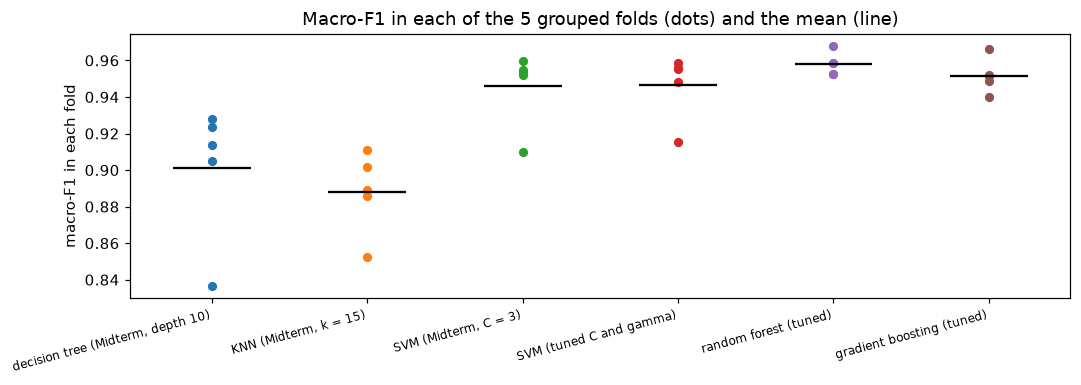

In [11]:
def fold_plot(names, title):
    fig, ax = plt.subplots(figsize=(10, 3.6))
    for i, n in enumerate(names):
        f = RESULTS[n]["folds"]
        ax.scatter([i] * len(f), f, s=25)
        ax.hlines(f.mean(), i - 0.25, i + 0.25, color="black")
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=15, ha="right", fontsize=8)
    ax.set_ylabel("macro-F1 in each fold"); ax.set_title(title)
    plt.tight_layout(); plt.show()

fold_plot(["decision tree (Midterm, depth 10)", "KNN (Midterm, k = 15)", "SVM (Midterm, C = 3)",
           "SVM (tuned C and gamma)", "random forest (tuned)", "gradient boosting (tuned)"],
          "Macro-F1 in each of the 5 grouped folds (dots) and the mean (line)")

**What the tuning shows**
* **Random forest: CV 0.958 ± 0.006**, the best mean and by far the smallest spread. The single decision tree from the Midterm has 0.901 ± 0.033 (train 0.992): it memorises and jumps from fold to fold. Averaging 300 different trees makes the result about **5 times steadier**, which was the Midterm weakness the plan aimed at.
  * `max_features = "sqrt"` beats 0.5: letting each question see only 5 of the 25 inputs makes the trees more different from each other, so their votes cancel more errors.
  * `max_depth = None` and `20` tie, because the trees rarely grow deeper than 20 questions anyway. Leaves of 1 beat leaves of 3: the vote of many trees already smooths what single deep trees memorise.
* **Gradient boosting: CV 0.952 ± 0.008.** All five best settings use `min_samples_leaf = 20`, the middle of the three values tried (10, 20, 40): a medium brake against fitting single listings worked best here.
* **SVM with `C` and `gamma` tuned together: 0.947 ± 0.016**, against 0.946 with the Midterm setting. Tuning the second setting gains nothing that the spread can confirm. The Midterm SVM was already close to its best.
* In the fold plot, the two ensembles' dots sit close together, while the tree's and KNN's are scattered.

## 3. Unsupervised analysis: the shape of the catalogue without the labels

> **In plain words.** Up to now every model was *told* the type of each training listing. Here we hide the types and ask what structure the numbers have by themselves.
> * **PCA** builds new axes that are mixtures of the inputs, ordered by how much of the variation they capture. If a few axes capture almost everything, the inputs repeat each other.
> * **k-means** puts the listings into *k* groups of similar listings, without knowing their types. Afterwards we check how the groups line up with the types and with the model's errors.
>
> Both are fitted on the **training rows only**, and both need scaled inputs, otherwise the price (hundreds of thousands of tenge) would drown the sizes (tens of centimetres).

### 3.1 PCA on the nine numeric inputs

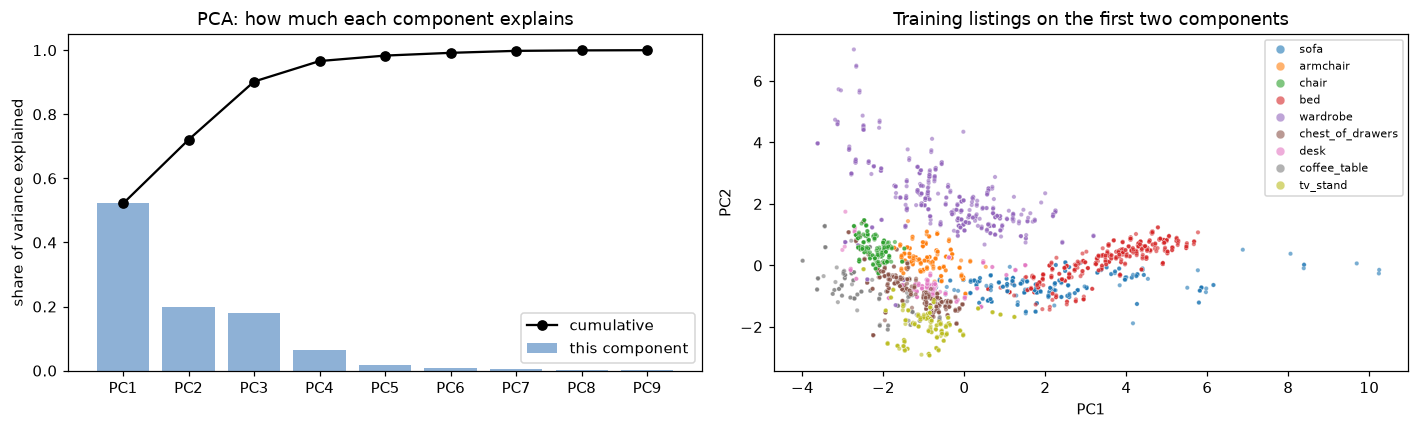

cumulative explained variance: {'PC1': 0.522, 'PC2': 0.721, 'PC3': 0.902, 'PC4': 0.966, 'PC5': 0.983, 'PC6': 0.992, 'PC7': 0.998, 'PC8': 0.999, 'PC9': 1.0}


,PC1,PC2,PC3
width_cm,0.41,-0.20,-0.25
depth_cm,0.41,0.06,0.32
height_cm,0.03,0.62,-0.42
footprint_m2,0.44,-0.01,0.16
volume_m3,0.44,0.17,0.02
height_to_width,-0.22,0.62,-0.02
depth_to_width,-0.02,0.27,0.69
log_price,0.32,0.05,-0.39
log_price_per_m3,-0.35,-0.28,-0.11


In [12]:
scaler_num = StandardScaler().fit(X_train[NUMERIC])
Z = scaler_num.transform(X_train[NUMERIC])
pca = PCA(random_state=RANDOM_STATE).fit(Z)
explained = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(len(NUMERIC))])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(explained.index, explained, color="#8EB1D6", label="this component")
axes[0].plot(explained.index, explained.cumsum(), "o-", color="black", label="cumulative")
axes[0].set_ylabel("share of variance explained"); axes[0].set_title("PCA: how much each component explains"); axes[0].legend()
P = pca.transform(Z)[:, :2]
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=y_train.values, hue_order=TYPES, s=8, alpha=0.6, ax=axes[1])
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("Training listings on the first two components")
axes[1].legend(fontsize=7, markerscale=2, loc="best")
plt.tight_layout(); plt.show()

print("cumulative explained variance:", explained.cumsum().round(3).to_dict())
pd.DataFrame(pca.components_[:3].T, index=NUMERIC, columns=["PC1", "PC2", "PC3"]).round(2)

**What PCA shows**
* **3 components explain 90%** of the variation of the nine numeric inputs, 4 explain 97%. The nine inputs carry about three independent directions, because six of them are built from the same three sizes and the price.
* Reading the weights in the table:
  * **PC1 = how big.** Width, depth, footprint and volume all weigh about +0.4.
  * **PC2 = how tall.** Height and height/width weigh +0.62.
  * **PC3 = deep and low vs shallow and tall.** Depth/width +0.69, height -0.42.
* On the map, wardrobes stand apart at the top (tall), and beds and sofas stretch to the right (big). Chests of drawers, TV stands, desks and coffee tables overlap in the lower left. That overlap is where the models make most of their mistakes (section 5).
* A 2-D map only shows 72% of the variation, so the overlap in the picture is partly the projection. It is a hint, not proof.

### 3.2 k-means: how many natural groups?

> **In plain words.** The *silhouette* score (from -1 to 1) says how well each listing sits inside its own group compared with the nearest other group. Higher = cleaner groups. We cluster on four inputs a person would use to describe a piece of furniture: height, width, depth and (log) price.

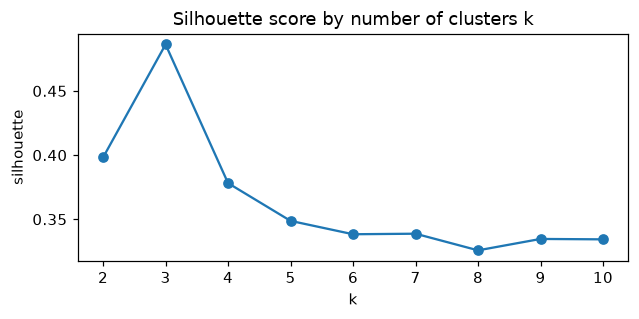

k = 3: silhouette 0.486 | ARI of 4 other random starts vs the first: [1.0, 1.0, 1.0, 1.0]


k = 6: silhouette 0.338 | ARI of 4 other random starts vs the first: [0.653, 0.869, 0.728, 0.871]


k = 9: silhouette 0.335 | ARI of 4 other random starts vs the first: [0.727, 0.683, 0.733, 0.736]


In [13]:
CLUSTER_INPUTS = ["height_cm", "width_cm", "depth_cm", "log_price"]
scaler_cl = StandardScaler().fit(X_train[CLUSTER_INPUTS])
Zc = scaler_cl.transform(X_train[CLUSTER_INPUTS])

sil = {k: silhouette_score(Zc, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Zc)) for k in range(2, 11)}
ax = pd.Series(sil).plot(marker="o", figsize=(6, 3), title="Silhouette score by number of clusters k")
ax.set_xlabel("k"); ax.set_ylabel("silhouette"); plt.tight_layout(); plt.show()

# Stability: run k-means with 5 different random starts and compare the groupings (ARI: 1 = identical)
def stability(k):
    runs = [KMeans(k, n_init=10, random_state=s).fit_predict(Zc) for s in range(5)]
    return [round(adjusted_rand_score(runs[0], r), 3) for r in runs[1:]]

for k in [3, 6, 9]:
    print(f"k = {k}: silhouette {sil[k]:.3f} | ARI of 4 other random starts vs the first: {stability(k)}")

**How many groups?**
* The silhouette score is highest at **k = 3** (0.49) and falls to about 0.34 for 6 to 10 groups.
* **k = 3 is perfectly stable:** five different random starts give exactly the same groups (ARI = 1.0).
* **k = 6 and k = 9 are not stable:** ARI 0.65 to 0.87. The finer groups change when only the random start changes, so we do not treat them as real groups.

We keep k = 3.

In [14]:
km3 = KMeans(3, n_init=10, random_state=RANDOM_STATE).fit(Zc)
clusters = pd.Series(km3.labels_, index=X_train.index, name="cluster")

# Describe each cluster with real numbers: median size and price, and its types
desc = X_train[["height_cm", "width_cm", "depth_cm"]].assign(price_kzt=train["price_kzt"]).groupby(clusters).median().round(0)
desc["listings"] = clusters.value_counts().sort_index()
display(desc)
display(pd.crosstab(clusters, y_train).reindex(columns=TYPES))

,height_cm,width_cm,depth_cm,price_kzt,listings
cluster,,,,,
0,212.0,120.0,50.0,355930.0,528
1,78.0,100.0,50.0,168360.0,1807
2,91.0,212.0,151.0,390380.0,792


furniture_type,sofa,armchair,chair,bed,wardrobe,chest_of_drawers,desk,coffee_table,tv_stand
cluster,,,,,,,,,
0,0,0,0,0,528,0,0,0,0
1,47,264,247,14,31,523,242,134,305
2,258,5,0,511,0,0,12,0,6


In [15]:
# Real examples from each cluster (names are shown only to explain, they are never a model input)
for c in sorted(clusters.unique()):
    print(f"--- cluster {c} ---")
    print(train.loc[clusters == c, ["name", "furniture_type", "width_cm", "depth_cm", "height_cm", "price_kzt"]]
          .sample(5, random_state=RANDOM_STATE).to_string(index=False))

--- cluster 0 ---
                                         name furniture_type  width_cm  depth_cm  height_cm  price_kzt
       Распашной шкаф Ренар 4.1-240x260 Латте       wardrobe     240.0      60.0      260.0   688970.0
   Распашной шкаф Виклу 2-90x210 Серо-зеленый       wardrobe      90.0      54.0      210.0   413350.0
Распашной шкаф Авильтон 1.1-43x205 Графитовый       wardrobe      43.0      38.0      205.0    91800.0
    Распашной шкаф Висмар 4-204x240 Оливковый       wardrobe     203.8      52.0      240.0   574130.0
        Распашной шкаф Кимбол 4-240x240 Белый       wardrobe     240.0      50.0      240.0   375070.0
--- cluster 1 ---
                                              name   furniture_type  width_cm  depth_cm  height_cm  price_kzt
                    Тумба Кимбол 90x90 Дуб Барбера chest_of_drawers      90.0      40.0       89.6   107110.0
                    Журнальный стол Дарби-1 Черный     coffee_table      80.0      80.0       40.0   168360.0
     Кресло пово

**What the three groups are** (from the medians, the type counts and the real examples)

| Cluster | Typical listing | Contents |
|---|---|---|
| 0: **tall** | 212 cm high, 120 wide, 50 deep | only wardrobes (528 of the 559 in training) |
| 1: **mid-height, mid-size** | 78 cm high, 100 wide, 50 deep | everything else: chests, TV stands, desks, chairs, armchairs, coffee tables, some sofas |
| 2: **big and deep** | 91 cm high, 212 wide, 151 deep | beds and most sofas |

Without being told any type, k-means rediscovers the same split the Midterm's depth-3 decision tree found: height first, then overall size. The groups are a summary of *shape*, not of type: cluster 1 alone holds seven types. So these clusters do not prove that the store's nine categories are "natural". They show that two of them (wardrobes, and beds/sofas together) are easy to separate by size, and the rest are not.

### 3.3 Linking the structure to the models

> **In plain words.** Two checks connect sections 2 and 3:
> 1. **Where does the best model fail?** Each training listing gets a prediction from a model that did not see its series (cross-validated predictions). We then count the error rate inside each cluster.
> 2. **Does PCA help a model?** KNN measures distances, and our nine numeric inputs repeat each other (they are all built from three sizes and a price). We put PCA *inside* the pipeline, so it is fitted on the training part of every fold, and compare KNN with and without it.

In [16]:
best_so_far = max((n for n in RESULTS if not n.startswith("dummy")), key=lambda n: RESULTS[n]["folds"].mean())
oof = cross_val_predict(RESULTS[best_so_far]["pipe"], X_train, y_train, groups=g_train, cv=cv)
err = pd.Series(oof != y_train.values, index=X_train.index)

print("best model so far (by CV):", best_so_far)
print(pd.DataFrame({"listings": clusters.value_counts().sort_index(),
                    "errors": err.groupby(clusters).sum(),
                    "error rate": err.groupby(clusters).mean().round(3)}).to_string())

oof_s = pd.Series(oof, index=X_train.index)
mix = pd.crosstab(clusters[err], (y_train + " -> " + oof_s)[err])
print("\nMost common mistakes in each cluster:")
for c in mix.index:
    print(f"  cluster {c}:", mix.loc[c].sort_values(ascending=False).head(3).to_dict())

best model so far (by CV): random forest (tuned)
         listings  errors  error rate
cluster                              
0             528       0       0.000
1            1807     113       0.063
2             792      11       0.014

Most common mistakes in each cluster:
  cluster 1: {'tv_stand -> chest_of_drawers': 20, 'chest_of_drawers -> tv_stand': 16, 'tv_stand -> desk': 13}
  cluster 2: {'tv_stand -> desk': 6, 'desk -> sofa': 2, 'bed -> sofa': 2}


In [17]:
pca_knn = {}
for n_comp in [None, 3, 4, 5]:
    steps = [("prep", make_prep())]
    if n_comp:
        steps.append(("pca", PCA(n_components=n_comp, random_state=RANDOM_STATE)))
    steps.append(("model", KNeighborsClassifier(n_neighbors=15, weights="distance")))
    r = cross_validate(Pipeline(steps), X_train, y_train, groups=g_train, cv=cv, scoring="f1_macro")
    pca_knn["no PCA" if n_comp is None else f"PCA, {n_comp} components"] = (r["test_score"].mean(), r["test_score"].std())
pd.DataFrame(pca_knn, index=["CV macro-F1", "CV sd"]).T.round(3)

,CV macro-F1,CV sd
no PCA,0.888,0.020
"PCA, 3 components",0.882,0.017
"PCA, 4 components",0.900,0.030
"PCA, 5 components",0.894,0.028


**What the structure says about the models**
* **The errors live in cluster 1.** With cross-validated predictions of the best model so far (the tuned random forest):
  * the tall cluster has **0 errors** in 528 listings;
  * the big cluster has 1.4%;
  * the mid-size cluster has **6.3%** (113 of the 124 errors).
* Inside cluster 1, the top mistakes are TV stand ↔ chest of drawers (36) and TV stand → desk (13). These are listings with nearly the same width, depth and height: in numbers, a low cabinet, a TV stand and a small desk can look the same. This is the weakness that a new source of information has to address in the Final (section 6).
* **PCA inside the KNN pipeline does not clearly help.**
  * KNN without PCA: 0.888 ± 0.020.
  * With 4 components: 0.900 ± 0.030.
  * With 3 components: 0.882.

  The best gain (+0.012) is smaller than the spread, so we cannot claim an improvement. KNN stays the weakest real model, and PCA is not used in the final model.

## 4. Neural network (MLP)

> **In plain words.** A multilayer perceptron is a stack of layers of simple units. Each unit takes a weighted sum of its inputs and passes it through a simple bend (ReLU: negative values become 0). Training goes over the data many times (**epochs**); after each small batch of rows, the weights are nudged so that the error (the **loss**) gets smaller.
>
> Before comparing it with other models we check that it actually learned: we draw its **learning curve**, the score on the rows it trains on and on rows it does not see, epoch by epoch.
> * Validation score still rising: train longer.
> * Validation flat (a **plateau**): more epochs won't help.
> * Validation falling while training keeps rising: **overfitting** (memorising).

**Why we don't use the built-in `early_stopping`.** It holds out a *random* 10% of rows for validation. That ignores our series groups, so colour twins would sit on both sides and the curve would look too good. We build our own **grouped** validation split instead, from the training rows only.

### 4.1 Learning curve

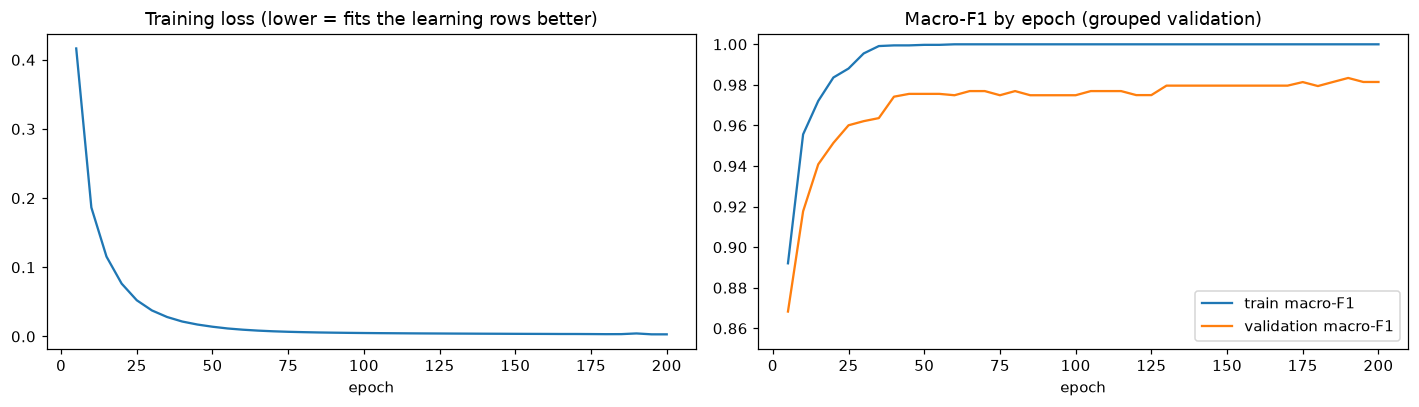

learning rows: 2407, validation rows: 720 (no series on both sides)


,loss,train macro-F1,validation macro-F1
epoch,,,
10,0.186,0.956,0.918
20,0.076,0.984,0.951
50,0.014,1.000,0.976
100,0.005,1.000,0.975
150,0.004,1.000,0.980
200,0.003,1.000,0.981


In [18]:
tr_i, va_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
                  .split(X_train, y_train, g_train))
prep_lc = make_prep().fit(X_train.iloc[tr_i])                 # fitted on the learning part only
A, B = prep_lc.transform(X_train.iloc[tr_i]), prep_lc.transform(X_train.iloc[va_i])
ya, yb = y_train.iloc[tr_i], y_train.iloc[va_i]
assert not set(g_train.iloc[tr_i]) & set(g_train.iloc[va_i])

mlp_lc = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=64, learning_rate_init=1e-3,
                       random_state=RANDOM_STATE)
classes = np.array(sorted(y_train.unique()))
curve = []
for epoch in range(1, 201):
    mlp_lc.partial_fit(A, ya, classes=classes)                # one pass over the learning rows
    if epoch % 5 == 0:
        curve.append({"epoch": epoch, "loss": mlp_lc.loss_,
                      "train macro-F1": f1_score(ya, mlp_lc.predict(A), average="macro"),
                      "validation macro-F1": f1_score(yb, mlp_lc.predict(B), average="macro")})
curve = pd.DataFrame(curve).set_index("epoch")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
curve["loss"].plot(ax=axes[0], title="Training loss (lower = fits the learning rows better)")
curve[["train macro-F1", "validation macro-F1"]].plot(ax=axes[1], title="Macro-F1 by epoch (grouped validation)")
axes[0].set_xlabel("epoch"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0.85, 1.005)
plt.tight_layout(); plt.show()
print(f"learning rows: {len(tr_i)}, validation rows: {len(va_i)} (no series on both sides)")
curve.iloc[[1, 3, 9, 19, 29, 39]].round(3)

**Reading the learning curve**
* The loss falls fast during the first 25 epochs and is flat after about 75: training has **converged**.
* Training macro-F1 reaches 1.000 by epoch 50: the network can fit every learning row.
* Validation macro-F1 rises to about 0.975 by epoch 50, then stays on a **plateau** between 0.975 and 0.981 up to epoch 200. More epochs do not help, and the validation score does not fall, so the overfitting is mild: the gap between train (1.00) and validation (0.98) stays the same and does not grow.
* This validation set is one grouped split of 720 listings. It happens to be easier than average, so its 0.98 is higher than the 5-fold CV score below. The curve is used to check *how* the network learns; the score for the comparison comes from the same 5 folds as every other model.

### 4.2 Choosing the architecture and the penalty

> **In plain words.** Two settings matter most: the **size** of the network (`hidden_layer_sizes`: (32,) = one layer of 32 units, (128, 64) = two layers) and `alpha`, a penalty on large weights that keeps the network from memorising. We try 6 combinations with the same grouped folds as every other model. `max_iter = 300` epochs, and we check afterwards whether training stopped because it converged or because it ran out of epochs.

In [19]:
mlp_search = GridSearchCV(
    make_pipeline(MLPClassifier(max_iter=300, random_state=RANDOM_STATE)),
    {"model__hidden_layer_sizes": [(32,), (64, 32), (128, 64)], "model__alpha": [1e-4, 1e-2]},
    cv=cv, scoring="f1_macro", return_train_score=True,
).fit(X_train, y_train, groups=g_train)
keep_search("MLP (tuned)", mlp_search)
best_mlp = mlp_search.best_estimator_.named_steps["model"]
print(f"chosen MLP stopped after {best_mlp.n_iter_} epochs of max {best_mlp.max_iter}"
      f" -> {'converged (the loss stopped improving)' if best_mlp.n_iter_ < best_mlp.max_iter else 'hit the epoch limit'}")
t = top_settings(mlp_search, n=6)
t["mean_train_score"] = pd.DataFrame(mlp_search.cv_results_).loc[t.index, "mean_train_score"].round(3)
t

MLP (tuned): {'model__alpha': 0.01, 'model__hidden_layer_sizes': (128, 64)}
    CV macro-F1 = 0.939 ± 0.011
chosen MLP stopped after 175 epochs of max 300 -> converged (the loss stopped improving)


,alpha,hidden_layer_sizes,mean_test_score,std_test_score,rank_test_score,mean_train_score
5,0.01,"(128, 64)",0.939,0.011,1,1.000
2,0.00,"(128, 64)",0.937,0.013,2,1.000
4,0.01,"(64, 32)",0.934,0.012,3,1.000
1,0.00,"(64, 32)",0.934,0.016,4,1.000
0,0.00,"(32,)",0.926,0.009,5,0.998
3,0.01,"(32,)",0.925,0.010,6,0.998


**The MLP against the other models**
* **Best MLP: two layers of 128 and 64 units, `alpha = 0.01`: CV 0.939 ± 0.011.** It converged after 175 epochs, before the 300-epoch limit.
* Bigger networks score a little higher (0.926 for one layer of 32 units, 0.939 for 128 + 64), and the stronger penalty helps slightly. All six settings fit the training folds almost perfectly (train 0.998 to 1.000).
* **It does not beat the earlier best models.** In CV it is below the random forest (0.958), boosting (0.952) and the SVM (0.947), and above KNN and the single tree. Why:
  * we have about 3,100 listings from only 359 groups;
  * the types are separated mostly by simple thresholds on height and size, which trees capture directly;
  * a neural network's strength is learning its own features from large or raw inputs (images, text). Here a person has already made the useful features (sizes, ratios, price per m³).
* The MLP is a reasonable model for this data, but not a better one. As the Midterm plan expected, a more flexible model does not remove the remaining errors: they come from what the numbers cannot show, not from the model's flexibility.

## 5. Fair comparison of every model, and the errors

> **In plain words.** One table, every model, the same rules:
> * the same 3,127 training listings and the same 5 grouped folds (CV mean and spread);
> * the same 793 test listings, opened once per model at the very end;
> * the same metric, **macro-F1**: the F1 score of each of the nine types, averaged with equal weight. The classes are unequal (coffee tables 4%, wardrobes 18%), so plain accuracy would let a model ignore the small types.
>
> The final model is chosen by the **CV mean only**. The test column is reported, not used for choosing.

In [20]:
order = ["dummy (most frequent)", "dummy (stratified)", "decision tree (Midterm, depth 10)", "KNN (Midterm, k = 15)",
         "SVM (Midterm, C = 3)", "SVM (tuned C and gamma)", "random forest (tuned)", "gradient boosting (tuned)", "MLP (tuned)"]
test_pred, rows = {}, []
for name in order:
    fitted = clone(RESULTS[name]["pipe"]).fit(X_train, y_train)
    test_pred[name] = fitted.predict(X_test)
    f = RESULTS[name]["folds"]
    rows.append({"model": name, "CV macro-F1": f.mean(), "CV sd": f.std(),
                 "test macro-F1": f1_score(y_test, test_pred[name], average="macro"),
                 "test accuracy": accuracy_score(y_test, test_pred[name])})
summary = pd.DataFrame(rows).set_index("model")
real_models = [n for n in order if not n.startswith("dummy")]
BEST = summary.loc[real_models, "CV macro-F1"].idxmax()
print("Chosen by CV mean:", BEST)
summary.round(3)

Chosen by CV mean: random forest (tuned)


,CV macro-F1,CV sd,test macro-F1,test accuracy
model,,,,
dummy (most frequent),0.034,0.000,0.033,0.177
dummy (stratified),0.114,0.003,0.122,0.144
"decision tree (Midterm, depth 10)",0.901,0.033,0.895,0.904
"KNN (Midterm, k = 15)",0.888,0.020,0.950,0.958
"SVM (Midterm, C = 3)",0.946,0.018,0.975,0.976
SVM (tuned C and gamma),0.947,0.016,0.980,0.981
random forest (tuned),0.958,0.006,0.969,0.971
gradient boosting (tuned),0.952,0.008,0.938,0.936
MLP (tuned),0.939,0.011,0.969,0.977


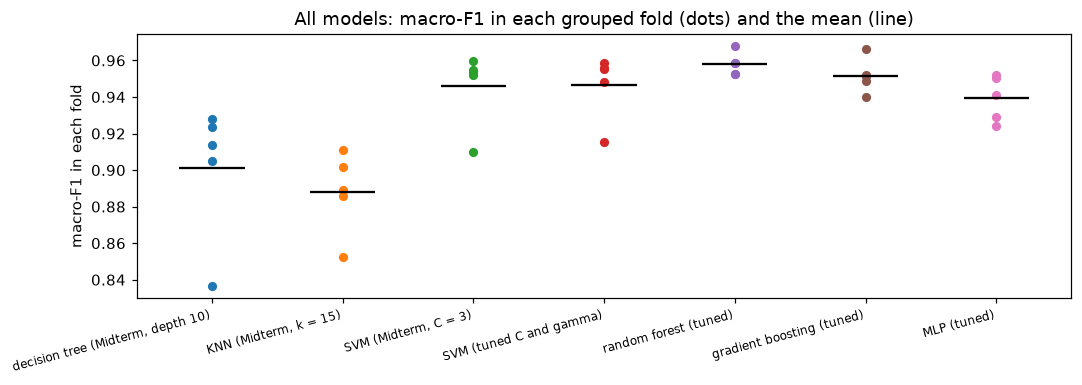

In [21]:
fold_plot(real_models, "All models: macro-F1 in each grouped fold (dots) and the mean (line)")

**The comparison**

* **Chosen model: the tuned random forest,** with the best CV mean (0.958) and the smallest spread (± 0.006).
* All seven real models are far above both dummies (0.034 and 0.114).
* **The test column ranks the top models differently.** The tuned SVM scores 0.980 on the test set, the forest 0.969 and the MLP 0.969. We still choose by CV, for two reasons:
  1. **CV is five checks on 3,127 listings; the test set is one check.** Choosing by the test score would mean picking the model that happens to be lucky on these 793 listings, and the test score would stop being an honest estimate.
  2. **The test set is smaller than it looks.** Its 793 listings belong to only 100 designs (groups), and a model gets all colours of a design right or wrong together. The forest's 23 test errors come from just **5 designs**, the SVM's 15 from **7 designs**. One design sold in five colours moves the test macro-F1 by about 0.01. So the test differences between the top three models are within this noise.
* **The order of the models makes sense:**
  * ensembles > SVM > MLP > single tree > KNN in CV;
  * the methods built for tabular threshold rules (trees and ensembles) do best;
  * KNN, which treats all 25 inputs as equally important distances, does worst.

### 5.1 Which types does each model get right?

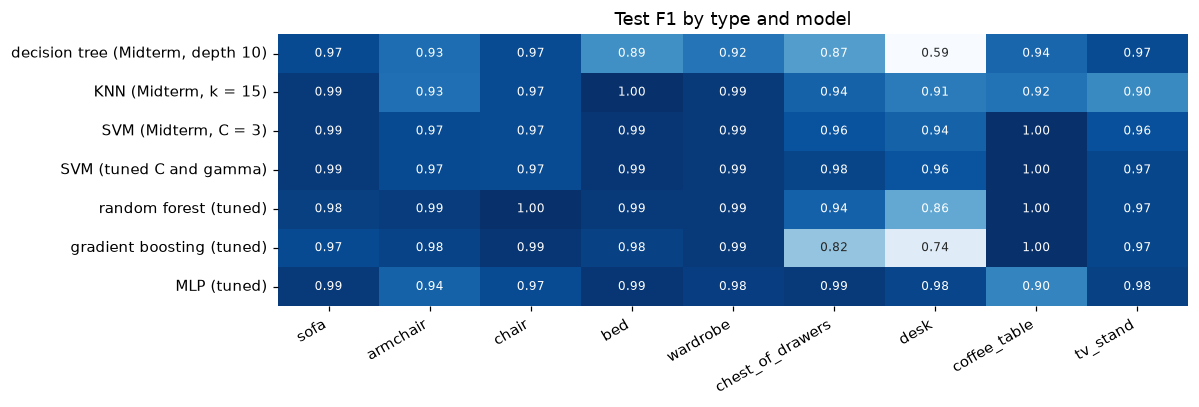

In [22]:
per_class = pd.DataFrame({n: classification_report(y_test, test_pred[n], labels=TYPES, output_dict=True, zero_division=0)
                          for n in real_models}).T
per_class_f1 = pd.DataFrame({t: per_class[t].apply(lambda d: d["f1-score"]) for t in TYPES})
plt.figure(figsize=(11, 3.8))
sns.heatmap(per_class_f1, annot=True, fmt=".2f", cmap="Blues", vmin=0.7, vmax=1, cbar=False, annot_kws={"fontsize": 8})
plt.title("Test F1 by type and model"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

### 5.2 The chosen model's confusion matrix

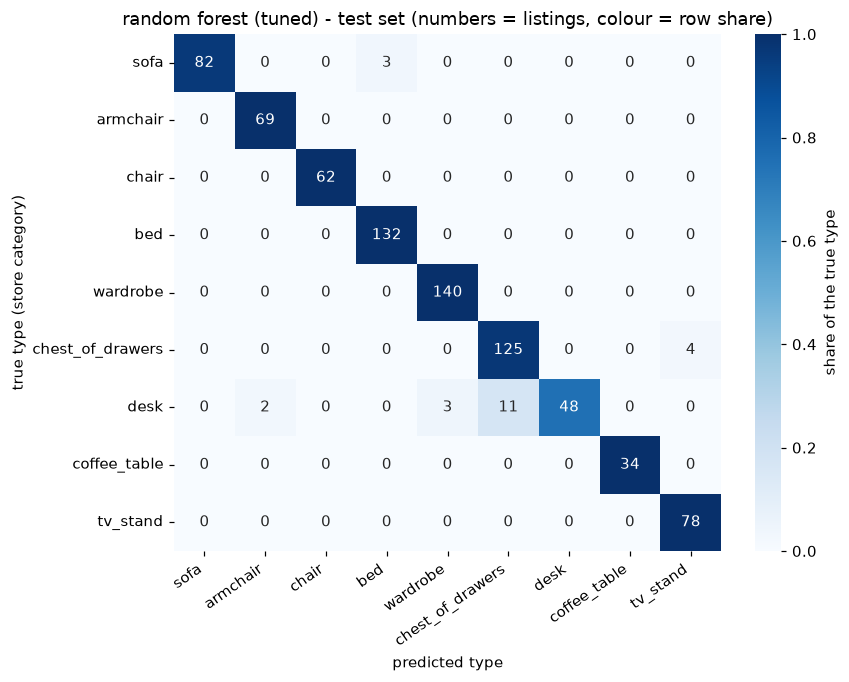

,true,predicted,n
0,desk,chest_of_drawers,11
1,chest_of_drawers,tv_stand,4
2,sofa,bed,3
3,desk,wardrobe,3
4,desk,armchair,2


In [23]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=TYPES)
    plt.figure(figsize=(8, 6.3))
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt="d", cmap="Blues",
                xticklabels=TYPES, yticklabels=TYPES, cbar_kws={"label": "share of the true type"})
    plt.xlabel("predicted type"); plt.ylabel("true type (store category)"); plt.title(title)
    plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
    return cm

cm = plot_confusion(y_test, test_pred[BEST], f"{BEST} - test set (numbers = listings, colour = row share)")
cm_df = pd.DataFrame(cm, index=TYPES, columns=TYPES)
pairs = cm_df.stack().rename("n").reset_index()
pairs.columns = ["true", "predicted", "n"]
pairs[(pairs["true"] != pairs["predicted"]) & (pairs["n"] > 0)].sort_values("n", ascending=False).head(8).reset_index(drop=True)

### 5.3 Errors across models: shared mistakes vs one model's mistakes

> **In plain words.** If *every* model gets a listing wrong, the problem is probably the listing (an odd shape, or a store label that is debatable). If only one model gets it wrong, that is a weakness of that model.

In [24]:
wrong = pd.DataFrame({n: test_pred[n] != y_test.values for n in real_models}, index=X_test.index)
test_view = test.assign(models_wrong=wrong.sum(axis=1), chosen_predicts=test_pred[BEST])
print("test listings that k of the 7 models get wrong:")
print(test_view["models_wrong"].value_counts().sort_index().to_string())

cols = ["name", "furniture_type", "chosen_predicts", "width_cm", "depth_cm", "height_cm", "price_kzt", "models_wrong"]
print("\nListings that every model gets wrong (names shown only to explain):")
display(test_view[test_view["models_wrong"] == len(real_models)][cols])

test listings that k of the 7 models get wrong:
models_wrong
0    655
1     99
2     14
3     12
5      9
6      1
7      3

Listings that every model gets wrong (names shown only to explain):


,name,furniture_type,chosen_predicts,width_cm,depth_cm,height_cm,price_kzt,models_wrong
2186,Письменный стол Пенни 132x55 Латте,desk,wardrobe,132.0,55.0,190.0,214300.0,7
2187,Письменный стол Пенни 132x55 Серо-зеленый,desk,wardrobe,132.0,55.0,190.0,214300.0,7
2188,Письменный стол Пенни 132x55 Белый,desk,wardrobe,132.0,55.0,190.0,214300.0,7


In [25]:
# What changed compared with the Midterm winner, on the same test listings?
mid = "SVM (Midterm, C = 3)"
fixed = (test_pred[mid] != y_test.values) & (test_pred[BEST] == y_test.values)
broken = (test_pred[mid] == y_test.values) & (test_pred[BEST] != y_test.values)
print(f"{BEST} vs {mid}: fixes {fixed.sum()} test listings, breaks {broken.sum()}")
show = ["name", "furniture_type", "width_cm", "depth_cm", "height_cm", "price_kzt"]
display(test.loc[fixed, show].assign(midterm_said=test_pred[mid][fixed]).head(8))
display(test.loc[broken, show].assign(now_says=test_pred[BEST][broken]).head(8))

random forest (tuned) vs SVM (Midterm, C = 3): fixes 12 test listings, breaks 16


,name,furniture_type,width_cm,depth_cm,height_cm,price_kzt,midterm_said
1034,Кресло Акапулько Бежевый-Синий/Черный,armchair,66.0,66.0,83.0,38210.0,chair
1035,Кресло Акапулько Бежевый-Бордовый/Черный,armchair,66.0,66.0,83.0,38210.0,chair
1036,Кресло Акапулько Бежевый-Оливковый/Черный,armchair,66.0,66.0,83.0,38210.0,chair
1037,Кресло Акапулько Оливковый/Черный,armchair,66.0,66.0,83.0,38210.0,chair
1508,Кровать Дарти 140 Ореx,bed,209.0,148.0,100.0,436320.0,sofa
1727,Кровать Леос 160 Молочный,bed,210.0,170.0,94.0,421010.0,sofa
2079,Письменный стол Енссон 120x50 Светло-бежевый,desk,120.0,50.0,76.0,91800.0,chest_of_drawers
2080,Письменный стол Енссон 120x50 Латте,desk,120.0,50.0,76.0,91800.0,chest_of_drawers


,name,furniture_type,width_cm,depth_cm,height_cm,price_kzt,now_says
442,Диван угловой Порту Рогожка Коричневый,sofa,226.0,155.0,90.0,359760.0,bed
443,Диван угловой Порту Рогожка Желтый,sofa,226.0,155.0,90.0,359760.0,bed
444,Диван угловой Порту Велюр Терракотовый,sofa,226.0,155.0,90.0,359760.0,bed
2146,Письменный стол Крейн-3 90x50 Черный древесный,desk,90.0,50.0,78.0,91800.0,chest_of_drawers
2147,Письменный стол Крейн-3 90x50 Орех Карини,desk,90.0,50.0,78.0,76490.0,chest_of_drawers
2148,Письменный стол Крейн-3 90x50 Дуб Золотистый/Ч...,desk,90.0,50.0,78.0,76490.0,chest_of_drawers
2149,Письменный стол Крейн-3 90x50 Графитовый/Черный,desk,90.0,50.0,78.0,76490.0,chest_of_drawers
2150,Письменный стол Крейн-3 90x50 Латте/Черный,desk,90.0,50.0,78.0,76490.0,chest_of_drawers


**What the errors show**
* **The type heatmap:**
  * all models are at 0.97 to 1.00 for sofas, armchairs, chairs, beds and wardrobes;
  * the differences between models are almost entirely in **chests of drawers, desks, coffee tables and TV stands**, the mid-size group of section 3;
  * boosting is weakest there (chest 0.82, desk 0.74 on the test set), and the MLP is strongest (chest 0.99, desk 0.98) but weaker on coffee tables (0.90).
* **The chosen forest's 23 test mistakes come from only five designs:**

  | Design | Listings | True type | Predicted as |
  |---|---|---|---|
  | "Крейн" desks (90 x 50 x 78 cm, 69,000 to 92,000 ₸) | 9 | desk | chest of drawers |
  | "Пенни" desks | 5 | desk | wardrobe (3), armchair (2) |
  | "Тумба Воямполь 150x64" | 4 | chest of drawers | TV stand |
  | "Порту" corner sofa (226 x 155 cm) | 3 | sofa | bed |
  | "Роналд" desks (130 x 50 x 82 cm) | 2 | desk | chest of drawers |

  The "Крейн" desks alone are 9 of the 23 errors. In numbers, a 90 x 50 x 78 cm item at that price is a small cabinet. The Midterm SVM got several of them right, which is the main reason the forest scores lower on this test set.
* **3 listings are wrong for every model:** "Письменный стол Пенни 132x55" in three colours, predicted as a wardrobe. Its listed height is 190 cm, because the desk has a tall shelving tower. No specification-based model can know that a 190 cm item is a desk. This is an odd item, not a model weakness.
* **Most test listings are easy:** 655 of 793 are right for all seven models, and only 13 are wrong for five or more.
* **Against the Midterm SVM**, the forest fixes 12 test listings and breaks 16.
  * It fixes the "Кресло Акапулько" armchairs (66 cm, 38,000 ₸, chair-sized), two beds and the "Енссон" desks.
  * It breaks several "Крейн" desks and three colours of the "Порту" corner sofa (226 x 155 cm, which in footprint looks like a bed).

  The two models make different mistakes on the same kind of borderline items. That is another sign that the remaining errors come from the information in the specifications, not from one model.

### 5.4 Save the chosen model for the Final's app

The Final needs a local app that loads a saved model and predicts on new input. The chosen pipeline (preparation + model) is fitted on all training rows and saved now, so the app will use exactly this model.

In [26]:
final_model = clone(RESULTS[BEST]["pipe"]).fit(X_train, y_train)
Path("models").mkdir(exist_ok=True)
joblib.dump({"pipeline": final_model, "features": FEATURES, "numeric": NUMERIC, "materials": MATERIALS,
             "name": BEST, "sklearn": sklearn.__version__}, "models/structured_best.joblib")

# Check: the reloaded model gives the same test predictions
reloaded = joblib.load("models/structured_best.joblib")["pipeline"]
assert (reloaded.predict(X_test) == final_model.predict(X_test)).all()
print("saved models/structured_best.joblib:", BEST, "| test macro-F1",
      round(f1_score(y_test, reloaded.predict(X_test), average="macro"), 3))

saved models/structured_best.joblib: random forest (tuned) | test macro-F1 0.969


## 6. Conclusions and limitations

**Answer to the question.** Yes. From width, depth, height, price, materials and colour alone, the type of a mebel.kz listing can be predicted for the nine types with a cross-validated macro-F1 of **0.958 ± 0.006** (tuned random forest; test 0.969). The baselines score 0.03 and 0.11.

**What the Endterm added**

| Step | Result | What it taught us |
|---|---|---|
| Fixes | 41 colour twins of test listings removed, 97 listings regrouped | Midterm numbers were nearly honest; the leak is now closed |
| Ensembles | forest 0.958 ± 0.006, boosting 0.952 ± 0.008 | averaging many trees fixes the single tree's instability (± 0.033) |
| SVM tuning | 0.947 (vs 0.946) | the Midterm SVM was already near its best |
| PCA / k-means | 3 stable shape groups; errors 0% / 1.4% / 6.3% | the hard cases are mid-size cabinets, desks and stands whose sizes overlap |
| MLP | 0.939 ± 0.011, converged, mild overfitting | more flexibility does not remove the remaining errors |

**What changed since the Midterm.**
* The best model by CV is now the random forest (Midterm: SVM).
* The weak spot is the same group, mid-size case furniture. Part of it shifted from "chest vs TV stand" to "small desk vs chest".

**Limitations, tied to the errors we saw**
* **The specifications cannot show function.** A 90 x 50 x 78 cm desk and a cabinet of the same size have the same numbers (the "Крейн" desks). A desk with a 190 cm shelving tower has a wardrobe's height (the "Пенни" desk). No model trained on these inputs can fix this.
* **Labels are the store's categories.** Some low cabinets named "Тумба" are filed as chests of drawers. There is no hand-checked ground truth, so part of the "errors" is label noise.
* **The test set holds only 100 designs.** Errors come in blocks of colour variants, so the test score is noisy (one design ≈ 0.01). The CV estimate is more reliable.
* **One store, one city, one price snapshot, no weight.** The material flags partly mirror the store's form templates (Midterm 2.4), so the model may not transfer to another marketplace.
* **Small searches.** The forest grid has 12 combinations, boosting 12 random combinations of 81, the MLP 6. Wider searches might add a little, but the spreads suggest not much.

### Plan for the Final: product photos

**Source.** The main product photo of each listing, from the same mebel.kz product pages.
* Each page's schema.org `Product` block (already used for name and price) has an `image` list. Checked on 7 November 2026 on the page of "Кровать Нордик 160".
* The photos are served from `cdn.servicecdn.ru`.

**Why photos and not text.** The text fields leak the answer:
* the product name contains its type word in 93% of listings (Midterm section 2.3);
* the description starts with the name.

Photos carry information the numbers miss, without spelling out the type.

**Lawful access.**
* mebel.kz's `robots.txt` explicitly allows `*.jpg` and `*.png`. Before collecting, we will also read the CDN's `robots.txt`.
* We will use the same polite settings as the Midterm: 2 connections, at least 0.7 s between requests, a User-Agent naming the project.
* The photos are used only for this course project and are not re-published.

**Linking to the same objects.**
* Photos are matched by `url`, so every photo belongs to an existing row, with the same groups and the **same 793 test listings**.
* We will report how many listings have no usable photo. For those, the combined model falls back to the structured model. Results will be reported on all test listings and on the ones that have photos.

**Hypothesis.** The remaining errors are mid-size items whose sizes overlap: desk vs chest of drawers vs TV stand. A photo shows what the numbers cannot: legs and an open top (desk), drawer fronts (chest), a low open niche (TV stand). So photos should mainly fix errors in the mid-size cluster (6.3% now).

**How the value will be tested.** On the same test listings, with macro-F1, compare:
1. the tuned random forest on specifications (saved now in `models/structured_best.joblib`);
2. a photo model;
3. a combined model (photo features + specifications).

We will also report the F1 of chests, TV stands and desks, the number of confusions among them, and what happens to the named listings ("Крейн", "Пенни", "Роналд", "Тумба Воямполь"). If the photos do not help, we will say so and show why.

**Methods.**
* A pretrained CNN (for example ResNet50 or EfficientNet with ImageNet weights, in Keras) used as a feature extractor + logistic regression, then fine-tuned if time allows.
* Compared with a small CNN we train ourselves, as the Final rubric asks.
* All learned processing is fitted on the training listings only.

**Feasibility.** About 4,000 photos at the polite rate is under an hour of collection. Feature extraction with a pretrained CNN runs on a laptop CPU.

**The local app.** A Streamlit page that loads the saved pipeline:
* the user enters width, depth, height, price, materials and colour (and later uploads a photo);
* the page shows the predicted type with its probability and rejects impossible sizes or prices.

## 7. Contributions and AI tools

The full table is in `CONTRIBUTIONS.md`. In short:

* **Responsibilities:** Sultanbek Zhumagali leads section 1 (grouping fixes), section 2 (ensembles and SVM tuning), section 4 (MLP), and fresh execution/model checks. Tamerlan Yessimov leads section 3 (PCA/clustering), section 5 (comparison and errors), section 6 (conclusions and Final plan), and consistency checks across the notebook, slides and documents. Each reviews the other's sections. Both rehearse, inspect the archive and upload it. Detailed assignments and timed speaking roles are in `CONTRIBUTIONS.md`.
* **AI tools:** Claude Code (Anthropic, Claude Opus 5.5) and OpenAI Codex.
  * Claude Code collected the requirements from Moodle, wrote a study guide for our preparation (not part of this archive), wrote the code of this notebook, drafted the interpretation texts, `CHANGES.md` and the slides, and checked mebel.kz's robots.txt for the Final plan. On 11 November it corrected the boosting wording found in the Codex review and re-ran this notebook from a fresh kernel.
  * Codex reviewed the local files and saved results, checked dataset/split counts, corrected the surname and listed inconsistencies to fix.

  The team is responsible for checking every result and explaining all sections.

  **Submission:** Wednesday 11 November 2026, 23:59; **defense:** Thursday 12 November 2026.
